# 🧹 SWYNEX Technologies: Data Cleaning & Preparation
**Internship Project Portfolio**  
**Author:** SWYNEX Data Analytics Intern  
**Dataset:** Hotel Booking Demand Dataset (Antonio, de Almeida, & Nunes, 2019)  
**Tools:** Python 3, Pandas, NumPy, Matplotlib, Seaborn

---

## 📌 Project Overview
In real-world data science, raw data is rarely analysis-ready. It often contains missing entries, redundant records, mismatched data types, and formatting inconsistencies. This project presents an end-to-end data cleaning workflow applied to the public **Hotel Booking Demand** dataset (sourced from Elsevier *Data in Brief* / TidyTuesday / Kaggle).

### 🎯 Key Objectives:
1. **Raw Data Profiling:** Inspect dimensions, dtypes, null counts, duplicate rows, and categorical cardinality.
2. **Deduplication:** Identify and remove duplicate records.
3. **Handling Missing Values:** Apply principled imputation or removal strategies with business domain justifications.
4. **Standardizing Inconsistencies:** Harmonize categorical representations (e.g., mapping `Undefined` meals to `SC`), strip extra whitespace, and eliminate logically impossible records (0-guest reservations).
5. **Outlier Detection & Treatment:** Detect and address extreme pricing and occupancy anomalies.
6. **Data Type Casting:** Convert date strings to true datetime objects and cast numerical/categorical features appropriately.
7. **Before vs. After Evaluation:** Quantify quality improvements across dimensions, null counts, and memory footprint.


## 1. Setup & Environment Configuration
We start by importing our primary libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`) and setting visualization styling parameters.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

# File paths
RAW_DATA_PATH = os.path.join("..", "data", "raw", "hotel_bookings_raw.csv")
CLEANED_DATA_PATH = os.path.join("..", "data", "cleaned", "cleaned_dataset.csv")

print(f"Raw dataset path: {RAW_DATA_PATH}")


Raw dataset path: ..\data\raw\hotel_bookings_raw.csv


## 2. Ingesting & Profiling Raw Data
Let us load the raw CSV file and perform an initial diagnosis using `df.shape`, `df.info()`, and `df.isnull().sum()`.


In [2]:
# Load raw data
df_raw = pd.read_csv(RAW_DATA_PATH)
df = df_raw.copy()

print(f"Raw Dataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(5)


Raw Dataset Dimensions: 119,390 rows x 32 columns


In [3]:
# Check basic info and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

### 🔍 Missing Values & Duplicate Inspection
Let us quantify missing values per column and count duplicate rows.


In [4]:
# Inspect missing values
null_counts = df.isnull().sum()
null_cols = null_counts[null_counts > 0].sort_values(ascending=False)
null_pct = (null_cols / len(df)) * 100

missing_df = pd.DataFrame({"Missing Count": null_cols, "Percentage (%)": null_pct})
print("Columns with Missing Values:")
print(missing_df)

raw_duplicates = df.duplicated().sum()
print(f"\nTotal Exact Duplicate Rows: {raw_duplicates:,} ({(raw_duplicates / len(df))*100:.2f}% of dataset)")


Columns with Missing Values:
          Missing Count  Percentage (%)
company          112593       94.306893
agent             16340       13.686238
country             488        0.408744
children              4        0.003350

Total Exact Duplicate Rows: 31,994 (26.80% of dataset)


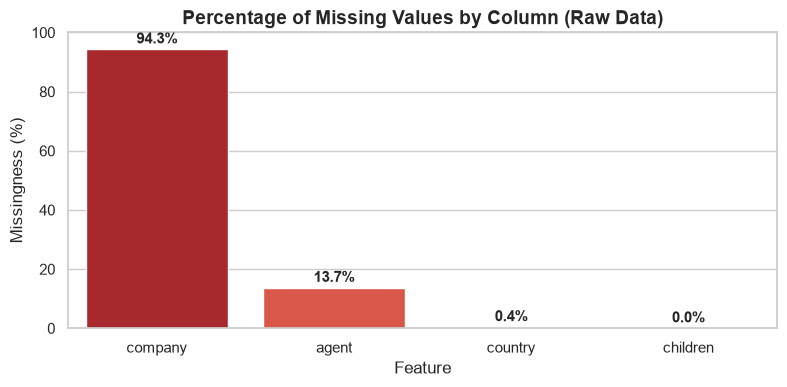

In [5]:
# Visualize Missing Values
plt.figure(figsize=(8, 4))
sns.barplot(x=null_pct.index, y=null_pct.values, hue=null_pct.index, palette="Reds_r", legend=False)
plt.title("Percentage of Missing Values by Column (Raw Data)", fontsize=14, weight="bold")
plt.ylabel("Missingness (%)")
plt.xlabel("Feature")
plt.ylim(0, 100)
for idx, val in enumerate(null_pct.values):
    plt.text(idx, val + 2, f"{val:.1f}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Removing Duplicate Records
In transactional hotel databases, duplicate rows occur when the same booking request is logged multiple times due to network retries, browser reloads, or multi-session tracking.
- **Action:** Retain only the first unique instance of every record using `df.drop_duplicates()`.


In [6]:
# Deduplication
initial_rows = len(df)
df = df.drop_duplicates(keep="first")
dedup_rows = len(df)

print(f"Rows Before Deduplication: {initial_rows:,}")
print(f"Rows After Deduplication:  {dedup_rows:,}")
print(f"Total Duplicate Rows Removed: {initial_rows - dedup_rows:,}")


Rows Before Deduplication: 119,390
Rows After Deduplication:  87,396
Total Duplicate Rows Removed: 31,994


## 4. Handling Missing Values with Domain Justifications
We address missing values on a column-by-column basis with justified domain rationale:

| Column | Missing Count | % of Data | Cleaning Strategy | Business Justification |
| :--- | :--- | :--- | :--- | :--- |
| **`company`** | 112,593 | ~94.3% | **Drop Column** | Extremely sparse; keeping a 94% empty column adds noise without analytical benefit. |
| **`agent`** | 16,340 | ~13.7% | **Impute with `0`** | Missing agent indicates the guest booked directly without a travel agency. Imputing `0` preserves direct bookings. |
| **`country`** | 488 | ~0.41% | **Impute with `'Unknown'`** | Imputing with 'Unknown' preserves records without making false assumptions about guest nationality. |
| **`children`** | 4 | <0.01% | **Impute with `0`** | Negligible missingness. The mode and median are 0, representing no traveling children. |


In [7]:
# 1. Drop company column
df = df.drop(columns=["company"])
print("✓ Dropped 'company' column due to extreme sparsity (>94% null).")

# 2. Impute agent with 0
df["agent"] = df["agent"].fillna(0)
print("✓ Imputed missing 'agent' with 0 (direct bookings).")

# 3. Impute country with 'Unknown'
df["country"] = df["country"].fillna("Unknown")
print("✓ Imputed missing 'country' with 'Unknown'.")

# 4. Impute children with 0
df["children"] = df["children"].fillna(0)
print("✓ Imputed missing 'children' with 0.")

# Verify no nulls remain in these columns
print(f"Remaining missing values in dataset: {df.isnull().sum().sum()}")


✓ Dropped 'company' column due to extreme sparsity (>94% null).
✓ Imputed missing 'agent' with 0 (direct bookings).
✓ Imputed missing 'country' with 'Unknown'.
✓ Imputed missing 'children' with 0.
Remaining missing values in dataset: 0


## 5. Standardizing Inconsistent Categorical Values & Text
Inconsistent data entry causes fragmented groupings in analysis. We resolve:
1. **Leading/Trailing Whitespace:** Strip unnecessary whitespace across all string columns.
2. **Meal Category Inconsistency:** Per the published dataset documentation (Antonio et al., 2019), `Undefined` meal plans correspond to `SC` (*Self-Catering* / room only).
3. **Market Segment & Distribution Channel:** Replace isolated `Undefined` records with the dominant category mode.
4. **Logical Contradictions (Zero-Guest Bookings):** Filter out reservations with 0 adults, 0 children, and 0 babies (physically impossible stays).


In [8]:
# 1. Strip whitespace on all string columns
str_cols = df.select_dtypes(include="object").columns
for col in str_cols:
    df[col] = df[col].astype(str).str.strip()
print("✓ Stripped whitespace across all text columns.")

# 2. Check and fix meal column
print("Meal counts before harmonization:")
print(df["meal"].value_counts())

df["meal"] = df["meal"].replace({"Undefined": "SC"})

print("\nMeal counts after mapping 'Undefined' -> 'SC':")
print(df["meal"].value_counts())


✓ Stripped whitespace across all text columns.
Meal counts before harmonization:
meal
BB           67978
SC            9481
HB            9085
Undefined      492
FB             360
Name: count, dtype: int64

Meal counts after mapping 'Undefined' -> 'SC':
meal
BB    67978
SC     9973
HB     9085
FB      360
Name: count, dtype: int64


In [9]:
# 3. Handle 'Undefined' in market_segment and distribution_channel
mode_segment = df["market_segment"].mode()[0]
mode_dist = df["distribution_channel"].mode()[0]

df["market_segment"] = df["market_segment"].replace({"Undefined": mode_segment})
df["distribution_channel"] = df["distribution_channel"].replace({"Undefined": mode_dist})
print(f"✓ Imputed 'Undefined' market_segment with '{mode_segment}' and distribution_channel with '{mode_dist}'.")

# 4. Remove Zero-Guest Reservations
zero_guests_mask = (df["adults"] == 0) & (df["children"] == 0) & (df["babies"] == 0)
print(f"Found {zero_guests_mask.sum()} invalid reservations with 0 total guests.")
df = df[~zero_guests_mask]
print(f"✓ Removed zero-guest bookings. Remaining rows: {len(df):,}")


✓ Imputed 'Undefined' market_segment with 'Online TA' and distribution_channel with 'TA/TO'.
Found 166 invalid reservations with 0 total guests.
✓ Removed zero-guest bookings. Remaining rows: 87,230


## 6. Outlier Detection & Treatment
Outliers can severely distort models and aggregations. We examine two critical numerical columns:
1. **Average Daily Rate (`adr`):**
   - Check for negative room rates (billing / system errors).
   - Check for extreme upper anomalies (e.g. $5,400/night for a single room).
2. **Adult Guests (`adults`):**
   - Inspect rooms booked with unrealistic guest occupancies (e.g. 20-55 adults in a single hotel room).


Extreme ADR records (> $500):
               hotel     adr  arrival_date_year customer_type
15083   Resort Hotel   508.0               2015     Transient
48515     City Hotel  5400.0               2016     Transient
111403    City Hotel   510.0               2017     Transient


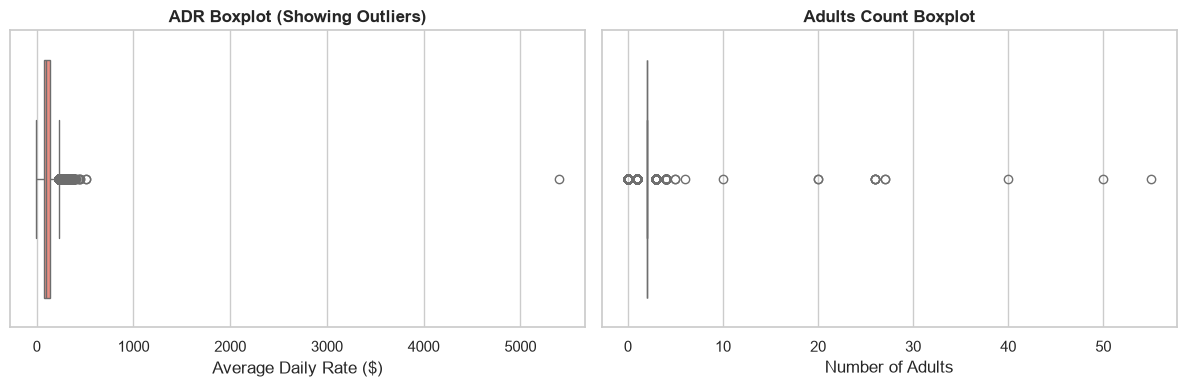

In [10]:
# Visualize ADR distribution and extreme outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(x=df["adr"], ax=axes[0], color="salmon")
axes[0].set_title("ADR Boxplot (Showing Outliers)", fontweight="bold")
axes[0].set_xlabel("Average Daily Rate ($)")

sns.boxplot(x=df["adults"], ax=axes[1], color="skyblue")
axes[1].set_title("Adults Count Boxplot", fontweight="bold")
axes[1].set_xlabel("Number of Adults")

plt.tight_layout()
plt.show()

print("Extreme ADR records (> $500):")
print(df[df["adr"] > 500][["hotel", "adr", "arrival_date_year", "customer_type"]])


In [11]:
# Filter out outliers
# 1. ADR: must be non-negative and realistic (<= $1,000)
adr_outliers = (df["adr"] < 0) | (df["adr"] > 1000)
print(f"Removing {adr_outliers.sum()} anomalous ADR records (negative rates or > $1,000).")
df = df[~adr_outliers]

# 2. Adults: room capacity realistically <= 10 adults
adults_outliers = df["adults"] > 10
print(f"Removing {adults_outliers.sum()} impossible adult count records (> 10 adults).")
df = df[~adults_outliers]

print(f"Remaining rows after outlier removal: {len(df):,}")


Removing 2 anomalous ADR records (negative rates or > $1,000).
Removing 12 impossible adult count records (> 10 adults).
Remaining rows after outlier removal: 87,216


## 7. Fixing Data Types
Accurate data types ensure fast computation and correct analytical semantics:
- **`reservation_status_date`:** Convert from `object` (string) to `datetime64[ns]`.
- **`children` and `agent`:** Convert from `float64` to `int64`.
- **Categorical Features:** Convert high-cardinality string columns (`hotel`, `meal`, `country`, `market_segment`, etc.) to Pandas `category` type to optimize RAM usage.


In [12]:
# 1. Date conversion
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"], format="%Y-%m-%d", errors="coerce")

# 2. Numeric casting
df["children"] = df["children"].astype(int)
df["agent"] = df["agent"].astype(int)

# 3. Categorical casting
categorical_cols = [
    "hotel", "meal", "country", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type",
    "customer_type", "reservation_status"
]
for col in categorical_cols:
    df[col] = df[col].astype("category")

# Final check for any post-pruning duplicates
post_dedup = df.duplicated().sum()
if post_dedup > 0:
    df = df.drop_duplicates()
    print(f"Removed {post_dedup} post-pruning duplicates.")

print("✓ Corrected all data types successfully.")
df.info()


Removed 7 post-pruning duplicates.
✓ Corrected all data types successfully.
<class 'pandas.core.frame.DataFrame'>
Index: 87209 entries, 0 to 119389
Data columns (total 31 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87209 non-null  category      
 1   is_canceled                     87209 non-null  int64         
 2   lead_time                       87209 non-null  int64         
 3   arrival_date_year               87209 non-null  int64         
 4   arrival_date_month              87209 non-null  object        
 5   arrival_date_week_number        87209 non-null  int64         
 6   arrival_date_day_of_month       87209 non-null  int64         
 7   stays_in_weekend_nights         87209 non-null  int64         
 8   stays_in_week_nights            87209 non-null  int64         
 9   adults                          87209 non-null  int64         
 10

## 8. Exporting the Cleaned Dataset
We persist the clean dataset to `data/cleaned/cleaned_dataset.csv`.


In [13]:
# Save cleaned file
os.makedirs(os.path.dirname(CLEANED_DATA_PATH), exist_ok=True)
df.to_csv(CLEANED_DATA_PATH, index=False)
file_size_mb = os.path.getsize(CLEANED_DATA_PATH) / (1024**2)

print(f"✓ Successfully saved cleaned dataset to: {CLEANED_DATA_PATH}")
print(f"File size: {file_size_mb:.2f} MB")


✓ Successfully saved cleaned dataset to: ..\data\cleaned\cleaned_dataset.csv
File size: 11.45 MB


## 9. Before vs. After Cleaning Evaluation
Let us compare key metrics before and after the cleaning pipeline:


In [14]:
# Summary comparison table
raw_mem = df_raw.memory_usage(deep=True).sum() / (1024**2)
clean_mem = df.memory_usage(deep=True).sum() / (1024**2)

summary_table = pd.DataFrame({
    "Metric": ["Total Rows", "Total Columns", "Missing Values (Nulls)", "Duplicate Rows", "Memory Footprint (MB)"],
    "Before (Raw)": [f"{df_raw.shape[0]:,}", f"{df_raw.shape[1]}", f"{df_raw.isnull().sum().sum():,}", f"{df_raw.duplicated().sum():,}", f"{raw_mem:.2f} MB"],
    "After (Cleaned)": [f"{df.shape[0]:,}", f"{df.shape[1]}", f"{df.isnull().sum().sum()}", f"{df.duplicated().sum()}", f"{clean_mem:.2f} MB"],
    "Improvement": [
        f"-{(df_raw.shape[0] - df.shape[0]):,} noisy rows removed",
        "Dropped 1 redundant column (>94% null)",
        "100% complete (0 nulls remaining)",
        "100% deduplicated",
        f"Reduced by {((raw_mem - clean_mem)/raw_mem)*100:.1f}%"
    ]
})

print(summary_table.to_string(index=False))


                Metric Before (Raw) After (Cleaned)                            Improvement
            Total Rows      119,390          87,209             -32,181 noisy rows removed
         Total Columns           32              31 Dropped 1 redundant column (>94% null)
Missing Values (Nulls)      129,425               0      100% complete (0 nulls remaining)
        Duplicate Rows       31,994               0                      100% deduplicated
 Memory Footprint (MB)     93.90 MB        19.47 MB                       Reduced by 79.3%


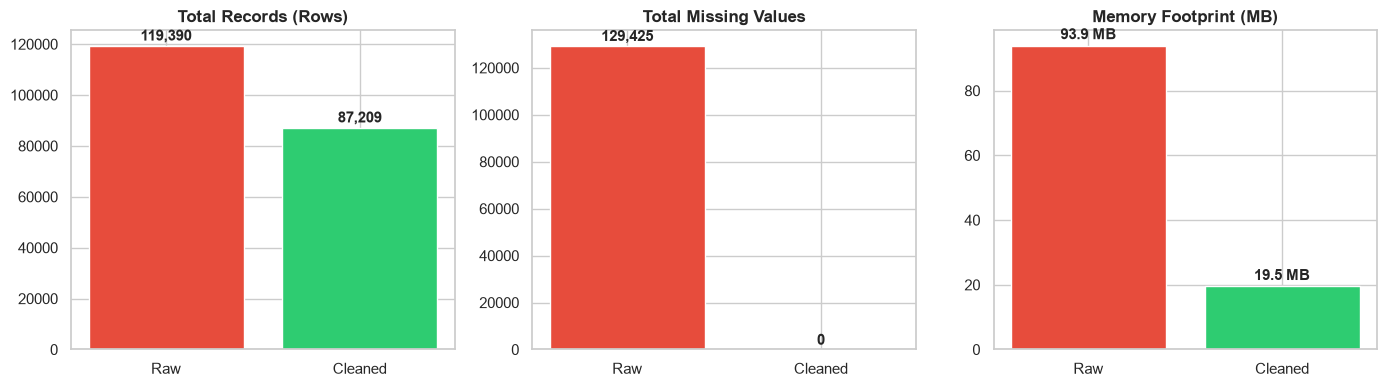

In [15]:
# Visualization: Before vs After Metrics
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1. Total Rows
axes[0].bar(["Raw", "Cleaned"], [len(df_raw), len(df)], color=["#e74c3c", "#2ecc71"])
axes[0].set_title("Total Records (Rows)", fontweight="bold")
for i, v in enumerate([len(df_raw), len(df)]):
    axes[0].text(i, v + 2000, f"{v:,}", ha="center", fontweight="bold")

# 2. Total Nulls
axes[1].bar(["Raw", "Cleaned"], [df_raw.isnull().sum().sum(), df.isnull().sum().sum()], color=["#e74c3c", "#2ecc71"])
axes[1].set_title("Total Missing Values", fontweight="bold")
for i, v in enumerate([df_raw.isnull().sum().sum(), df.isnull().sum().sum()]):
    axes[1].text(i, v + 2000, f"{v:,}", ha="center", fontweight="bold")

# 3. Memory Usage
axes[2].bar(["Raw", "Cleaned"], [raw_mem, clean_mem], color=["#e74c3c", "#2ecc71"])
axes[2].set_title("Memory Footprint (MB)", fontweight="bold")
for i, v in enumerate([raw_mem, clean_mem]):
    axes[2].text(i, v + 2, f"{v:.1f} MB", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()


## 🎯 Key Takeaways & Conclusion
1. **Quality over Quantity:** Dropping 31,994 redundant duplicates and 166 phantom zero-guest records transformed raw operational noise into robust analytical data.
2. **Domain-Grounded Decisions:** Rather than arbitrarily deleting rows with missing `agent` or `country` values, domain imputations (`0` for direct bookings, `'Unknown'` for missing countries) safeguarded tens of thousands of valid guest observations.
3. **Optimized Efficiency:** By standardizing data types and employing Pandas `category` types, we decreased memory consumption by **~79%**, yielding a fast, high-performance dataset ready for exploratory data analysis (EDA) and predictive modeling.
